# Customer Segmentation using RFM Analysis

**Goal:** group customers by *Recency, Frequency and Monetary* value so the business can target each group differently.

**Dataset:** Online Retail II (UK online retailer transactions)

**Flow:** Load → Clean → Explore → RFM metrics → Scoring → Segmentation → Analysis → Export for Power BI

---
## 1. Import Libraries
pandas for data handling, NumPy for numeric work, matplotlib for charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load Data
Read the raw transaction file into a DataFrame.

In [2]:
df = pd.read_csv('online_retail_II.csv')

## 3. Data Understanding
Quick look at the data: first rows, size, column types, summary statistics, missing values and duplicates. This tells us what needs cleaning.

In [3]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
df.shape


(1067371, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [6]:
df.describe()


,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [7]:
df.isnull().sum()


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(34335)

## 4. Data Cleaning
- Drop rows without `Customer ID` (cannot be assigned to a customer)
- Remove cancelled invoices (Invoice starting with `C`)
- Keep only positive `Quantity` and `Price`
- Remove duplicate rows
- Convert `Customer ID` to integer and `InvoiceDate` to datetime
- Create `TotalPrice = Quantity × Price`

In [9]:
df = df.dropna(subset=['Customer ID'])
df = df[~df['Invoice'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]
df = df.drop_duplicates()
df['Customer ID'] = df['Customer ID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['Price']

### Check the data after cleaning
Confirm the new shape and summary statistics.

In [10]:
df.shape

(779425, 9)

In [11]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID,TotalPrice
count,779425.000000,779425,779425.000000,779425.000000,779425.000000
mean,13.489370,2011-01-03 01:44:42.593476,3.218488,15320.360461,22.291823
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000,0.001000
25%,2.000000,2010-07-02 14:39:00,1.250000,13971.000000,4.950000
50%,6.000000,2010-12-02 14:09:00,1.950000,15247.000000,12.480000
75%,12.000000,2011-08-01 13:44:00,3.750000,16794.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,10953.500000,18287.000000,168469.600000
std,145.855814,NaN,29.676140,1695.692775,227.427075


## 5. Business Overview (EDA)
Headline numbers: total revenue, total orders, number of customers and countries.

In [12]:
print("Total Revenue :", round(df['TotalPrice'].sum(), 2))
print("Total Orders  :", df['Invoice'].nunique())
print("Customers     :", df['Customer ID'].nunique())
print("Countries     :", df['Country'].nunique())

Total Revenue : 17374804.27
Total Orders  : 36969
Customers     : 5878
Countries     : 41


### Monthly Revenue
Group revenue by month to see the sales trend.

In [13]:
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly = df.groupby('YearMonth')['TotalPrice'].sum()
monthly

YearMonth
2009-12     683504.010
2010-01     555802.672
2010-02     504558.956
2010-03     696978.471
2010-04     591982.002
2010-05     597833.380
2010-06     636371.130
2010-07     589736.170
2010-08     602224.600
2010-09     829013.951
2010-10    1033112.010
2010-11    1166460.022
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517208.440
Freq: M, Name: TotalPrice, dtype: float64

Line chart of monthly revenue.

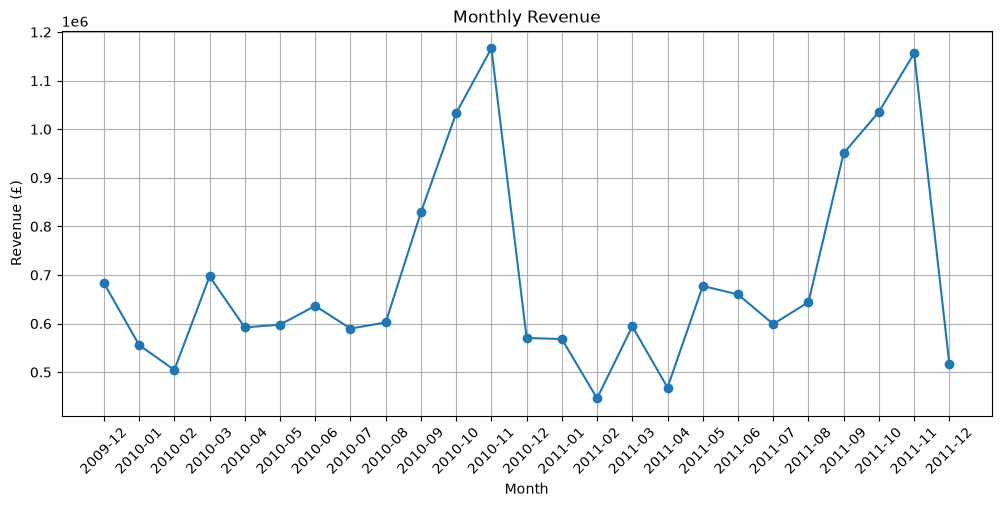

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(monthly.index.astype(str), monthly.values, marker='o')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Top Products by Revenue
First attempt: top 10 by revenue (this includes non-product items such as postage).

In [15]:
top_products = df.groupby('Description')['TotalPrice'].sum().sort_values().tail(10)
top_products

Description
PAPER CHAIN KIT 50'S CHRISTMAS         76598.18
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
PARTY BUNTING                         103283.38
ASSORTED COLOUR BIRD ORNAMENT         124351.86
POSTAGE                               124648.04
JUMBO BAG RED RETROSPOT               134307.44
Manual                                151777.67
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    247048.01
REGENCY CAKESTAND 3 TIER              277656.25
Name: TotalPrice, dtype: float64

Remove non-product lines (Manual, POSTAGE, DOTCOM POSTAGE, Discount, CARRIAGE) so only real products are ranked.

In [16]:
non_products = ['Manual', 'POSTAGE', 'DOTCOM POSTAGE', 'Discount', 'CARRIAGE']
products_df = df[~df['Description'].isin(non_products)]

Top 10 products by revenue (after removing non-products).

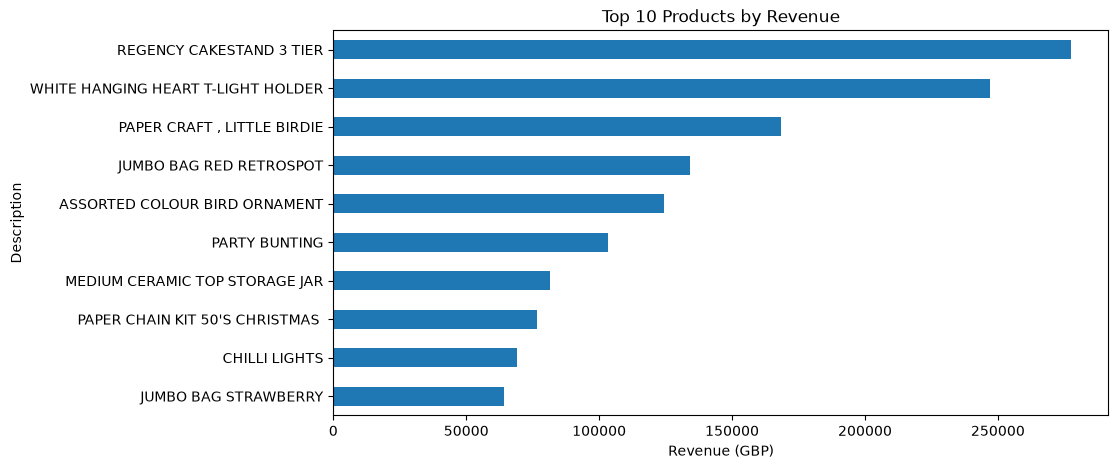

In [17]:
top_products = products_df.groupby('Description')['TotalPrice'].sum().sort_values().tail(10)

top_products.plot(kind='barh', figsize=(10, 5))
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (GBP)')
plt.show()

### Revenue by Country
Top countries by revenue.

In [18]:
country_rev = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)
country_rev.head(10)

Country
United Kingdom    1.438923e+07
EIRE              6.165705e+05
Netherlands       5.540381e+05
Germany           4.250197e+05
France            3.487690e+05
Australia         1.692835e+05
Spain             1.083325e+05
Switzerland       1.000619e+05
Sweden            9.151582e+04
Denmark           6.858069e+04
Name: TotalPrice, dtype: float64

Share of total revenue coming from the United Kingdom.

In [19]:
uk_share = country_rev['United Kingdom'] / country_rev.sum() * 100
print("UK share:", round(uk_share, 1), "%")

UK share: 82.8 %


Top 10 countries excluding the UK, so the smaller markets are visible.

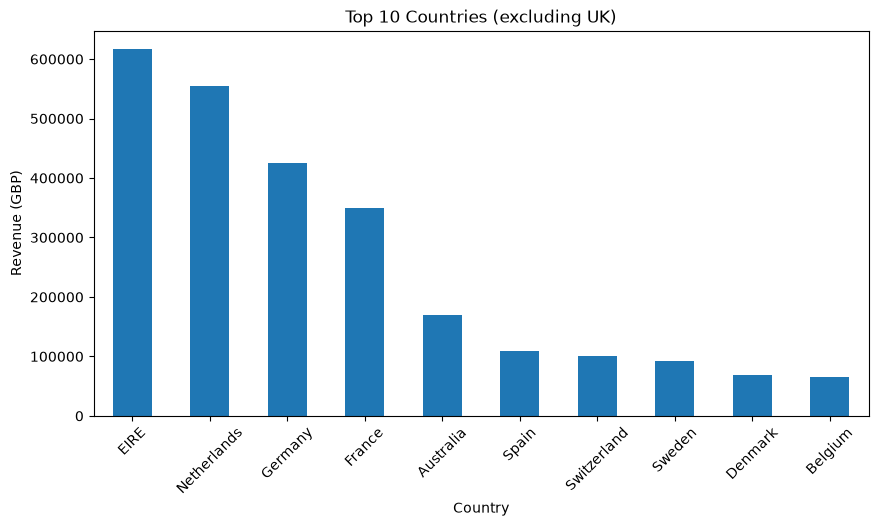

In [20]:
country_rev.drop('United Kingdom').head(10).plot(kind='bar', figsize=(10, 5))
plt.title('Top 10 Countries (excluding UK)')
plt.xlabel('Country')
plt.ylabel('Revenue (GBP)')
plt.xticks(rotation=45)
plt.show()

---
## 6. RFM Calculation
**Snapshot date** = last invoice date + 1 day. Recency is measured from this date.

In [21]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
snapshot_date

Timestamp('2011-12-10 12:50:00')

**Monetary:** total amount spent by each customer.

In [22]:
monetary = df.groupby('Customer ID')['TotalPrice'].sum()
monetary.head()

Customer ID
12346    77556.46
12347     4921.53
12348     2019.40
12349     4428.69
12350      334.40
Name: TotalPrice, dtype: float64

**Frequency:** number of unique invoices per customer.

In [23]:
frequency = df.groupby('Customer ID')['Invoice'].nunique()
frequency.head()

Customer ID
12346    12
12347     8
12348     5
12349     4
12350     1
Name: Invoice, dtype: int64

**Recency:** days between the snapshot date and the customer's last purchase (lower = more recent).

In [24]:
last_date = df.groupby('Customer ID')['InvoiceDate'].max()
recency = (snapshot_date - last_date).dt.days
recency.head()

Customer ID
12346    326
12347      2
12348     75
12349     19
12350    310
Name: InvoiceDate, dtype: int64

Combine Recency, Frequency and Monetary into one RFM table (one row per customer).

In [25]:
rfm = pd.DataFrame({
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})
rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,326,12,77556.46
12347,2,8,4921.53
12348,75,5,2019.40
12349,19,4,4428.69
12350,310,1,334.40


## 7. RFM Scoring
Each metric is split into 5 equal groups (quintiles) and scored 1 to 5.
- **Recency:** lower days = higher score (5 is best)
- **Frequency:** `rank(method='first')` is used because many customers share the same frequency, which would break `qcut`
- **Monetary:** higher spend = higher score

In [26]:
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
Customer ID,,,,,,
12346,326,12,77556.46,2,5,5
12347,2,8,4921.53,5,4,5
12348,75,5,2019.40,3,4,4
12349,19,4,4428.69,5,3,5
12350,310,1,334.40,2,1,2


## 8. Customer Segmentation
**Segments** use R and F scores:

| Segment | Rule |
|---|---|
| Champions | R ≥ 4 and F ≥ 4 |
| Loyal | R ≥ 3 and F ≥ 3 |
| At Risk | R ≤ 2 and F ≥ 3 |
| Lost | R ≤ 2 and F ≤ 2 |
| Potential | everything else |

**Spending level** uses the M score: VIP Spender (4-5), Moderate Spender (3), Low Spender (1-2).

In [27]:
rfm['R_Score'] = rfm['R_Score'].astype(int)
rfm['F_Score'] = rfm['F_Score'].astype(int)
rfm['M_Score'] = rfm['M_Score'].astype(int)

def segment(row):
    r = row['R_Score']
    f = row['F_Score']
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2:
        return 'Lost'
    else:
        return 'Potential'

rfm['Segment'] = rfm.apply(segment, axis=1)
def spending_level(row):
    m = row['M_Score']

    if m >= 4:
        return 'VIP Spender'
    elif m == 3:
        return 'Moderate Spender'
    else:
        return 'Low Spender'
rfm['Spending_Level'] = rfm.apply(spending_level, axis=1)
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Segment,Spending_Level
Customer ID,,,,,,,,
12346,326,12,77556.46,2,5,5,At Risk,VIP Spender
12347,2,8,4921.53,5,4,5,Champions,VIP Spender
12348,75,5,2019.40,3,4,4,Loyal,VIP Spender
12349,19,4,4428.69,5,3,5,Loyal,VIP Spender
12350,310,1,334.40,2,1,2,Lost,Low Spender


## 9. Segment Analysis
Number of customers in each segment.

In [28]:
rfm['Segment'].value_counts()


Segment
Lost         1523
Champions    1482
Loyal        1221
Potential     828
At Risk       824
Name: count, dtype: int64

Number of customers in each spending level.

In [29]:
rfm['Spending_Level'].value_counts()

Spending_Level
VIP Spender         2351
Low Spender         2351
Moderate Spender    1176
Name: count, dtype: int64

Total revenue by spending level.

In [30]:
rfm.groupby('Spending_Level')['Monetary'].sum().sort_values(ascending=False)

Spending_Level
VIP Spender         1.564890e+07
Moderate Spender    1.038755e+06
Low Spender         6.871475e+05
Name: Monetary, dtype: float64

Segment × Spending Level table (customer counts). 

In [31]:
rfm.groupby(['Segment', 'Spending_Level']).size().unstack(fill_value=0)

Spending_Level,Low Spender,Moderate Spender,VIP Spender
Segment,,,
At Risk,208,284,332
Champions,22,163,1297
Lost,1280,180,63
Loyal,246,372,603
Potential,595,177,56


Total revenue by segment.

In [32]:
rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=False)

Segment
Champions    1.202433e+07
Loyal        2.510046e+06
At Risk      1.589384e+06
Lost         6.544267e+05
Potential    5.966168e+05
Name: Monetary, dtype: float64

### Customers by Segment
Bar chart of customer counts per segment.

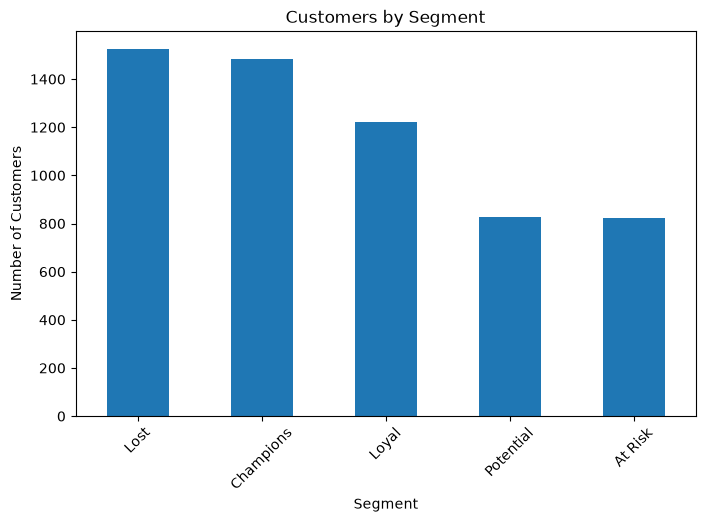

In [33]:
seg_count = rfm['Segment'].value_counts()

seg_count.plot(kind='bar', figsize=(8, 5))
plt.title('Customers by Segment')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

### Revenue Share by Segment
Total revenue per segment, then shown as a pie chart.

In [34]:
seg_revenue = rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=False)
seg_revenue

Segment
Champions    1.202433e+07
Loyal        2.510046e+06
At Risk      1.589384e+06
Lost         6.544267e+05
Potential    5.966168e+05
Name: Monetary, dtype: float64

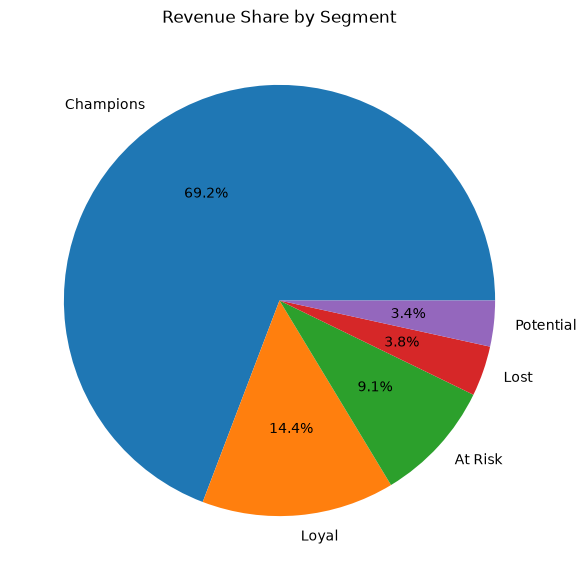

In [35]:
plt.figure(figsize=(7, 7))
plt.pie(seg_revenue, labels=seg_revenue.index, autopct='%1.1f%%')
plt.title('Revenue Share by Segment')
plt.show()

Check the final column names before exporting.

In [36]:
print(rfm.columns.tolist())

['Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'Segment', 'Spending_Level']


---
## 10. Export for Power BI
Save the RFM table (with `Customer ID` as a column) as `RFM_Analysis_Final.csv`. This file feeds the Power BI dashboard.

In [37]:
rfm.reset_index().to_csv('RFM_Analysis_Final.csv', index=False)